# Naive Bayes - Sentiment Analysis

This code loads and cleans the sample data and is copied over from Reviews_Feature_Engineering.ipynb (same as Logistic_Regression.ipynb).

In [1]:
import pandas as pd
import re

reviews_path = '../data/group_sample_seed48.csv'
df = pd.read_csv(reviews_path)

# Clean the data
# 1) Remove the 2 rows with a missing summary
# 2) Remove duplicate review text (same review posted under multiple product variants),
#    keeping the first copy, so the same review can't end up in both train and test
clean_df = df.dropna(subset=["Summary"]).copy()
clean_df = clean_df.drop_duplicates(subset=["Text"]).copy()

# Convert star ratings into three sentiment groups
sentiment_map = {
    1: "Negative",
    2: "Negative",
    3: "Neutral",
    4: "Positive",
    5: "Positive"
}

clean_df["Sentiment"] = clean_df["Score"].map(sentiment_map)

# Create a function that cleans pieces of text. This will clean up all of the html text thats in the reviews and then get rid of the extra
# whitespace after from cleaning html tags
def clean_text(text):
    # Remove HTML tags
    text = re.sub(r"<[^>]+>", " ", text)

    # Remove extra spaces and line breaks
    text = " ".join(text.split())

    return text


# Clean summaries and reviews without changing the original columns
clean_df["CleanSummary"] = clean_df["Summary"].apply(clean_text)
clean_df["CleanText"] = clean_df["Text"].apply(clean_text)

# Combine the summary and review to get one large text
clean_df["CombinedText"] = (clean_df["CleanSummary"] + " " + clean_df["CleanText"])

clean_df.head()

,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text,Sentiment,CleanSummary,CleanText,CombinedText
0,515539,B001U8CED2,A38XS08I7CNOUY,nncym,3,4,1,1300060800,Nasty Stuff - Cats Hate It!,I am owned by 5 cats and I foster another 17 c...,Negative,Nasty Stuff - Cats Hate It!,I am owned by 5 cats and I foster another 17 c...,Nasty Stuff - Cats Hate It! I am owned by 5 ca...
1,318059,B0024NKMEU,A1W1TQI2UZDY4R,Charles Baker,1,1,5,1269475200,Jerky spice,"This pack was exceptional for a ""newbie"" jerky...",Positive,Jerky spice,"This pack was exceptional for a ""newbie"" jerky...","Jerky spice This pack was exceptional for a ""n..."
2,34626,B000GQTP1S,A1DRP529AHD8F1,"Ralph Kuser ""seeking intelligent life""",1,2,5,1302393600,Nice and hot!,These chips are just hot enough to make them i...,Positive,Nice and hot!,These chips are just hot enough to make them i...,Nice and hot! These chips are just hot enough ...
3,131230,B00004RAMX,A275XT9A7OV1PL,wayfarer,0,0,1,1318550400,Junky gopher trap,This trap is very poor quality. Lock bar was t...,Negative,Junky gopher trap,This trap is very poor quality. Lock bar was t...,Junky gopher trap This trap is very poor quali...
4,312766,B003KJ0DDC,A18QI1MZI0L8KB,"L. Arters ""living with MS""",0,0,5,1349827200,Delicious,I love these whole wheat crackers by Lance! I...,Positive,Delicious,I love these whole wheat crackers by Lance! It...,Delicious I love these whole wheat crackers by...


This code splits the data the same way as the other models (80/20, seed 48) and builds Bag of Words features. Naive Bayes works with word counts, so it uses Bag of Words instead of TF-IDF.

In [2]:
from sklearn.model_selection import train_test_split

# Use 80% of the reviews for training and 20% for testing (same split as the other models)
train_df, test_df = train_test_split(
    clean_df,
    test_size=0.20,                 # 80/20 split
    random_state=48,                # Make it reproducible
    stratify=clean_df["Sentiment"]  # Keeps the class proportions similar
)

# Select the combined summary and review text as model inputs
train_text = train_df["CombinedText"]
test_text = test_df["CombinedText"]

# Select the sentiment labels that the models will learn to predict
train_labels = train_df["Sentiment"]
test_labels = test_df["Sentiment"]

# Import the Bag of Words tool (counts how many times each word appears)
from sklearn.feature_extraction.text import CountVectorizer

# Include individual words only
bow = CountVectorizer()

# Learn the vocabulary from training reviews
train_bow = bow.fit_transform(train_text)

# Use the same vocabulary for testing reviews
test_bow = bow.transform(test_text)

# Show the number of reviews and features
print("Training matrix shape:", train_bow.shape)
print("Testing matrix shape:", test_bow.shape)

Training matrix shape: (37008, 38244)
Testing matrix shape: (9253, 38244)


This code gives a reusable evaluation function (same as Logistic_Regression.ipynb), plus the macro-averaged scores used in the M3 comparison table.

In [3]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

labels = ["Negative", "Neutral", "Positive"]

def evaluate(name, true_labels, predicted_labels):
    print(name)
    print(classification_report(true_labels, predicted_labels, labels=labels, zero_division=0))

    ConfusionMatrixDisplay.from_predictions(
        true_labels,
        predicted_labels,
        labels=labels
    )
    plt.title(name)
    plt.show()


from sklearn.metrics import accuracy_score, precision_recall_fscore_support

def summary_scores(true_labels, predicted_labels):
    # Macro averages: each class counts equally (same as the comparison table)
    precision, recall, f1, _ = precision_recall_fscore_support(
        true_labels, predicted_labels, average="macro", zero_division=0
    )
    print(f"Accuracy:        {accuracy_score(true_labels, predicted_labels):.3f}")
    print(f"Macro precision: {precision:.3f}")
    print(f"Macro recall:    {recall:.3f}")
    print(f"Macro F1:        {f1:.3f}")

Naive Bayes

Training time: 0.08 seconds

Accuracy:        0.853
Macro precision: 0.666
Macro recall:    0.585
Macro F1:        0.603

Naive Bayes
              precision    recall  f1-score   support

    Negative       0.70      0.65      0.67      1331
     Neutral       0.41      0.14      0.21       709
    Positive       0.89      0.96      0.92      7213

    accuracy                           0.85      9253
   macro avg       0.67      0.58      0.60      9253
weighted avg       0.83      0.85      0.83      9253



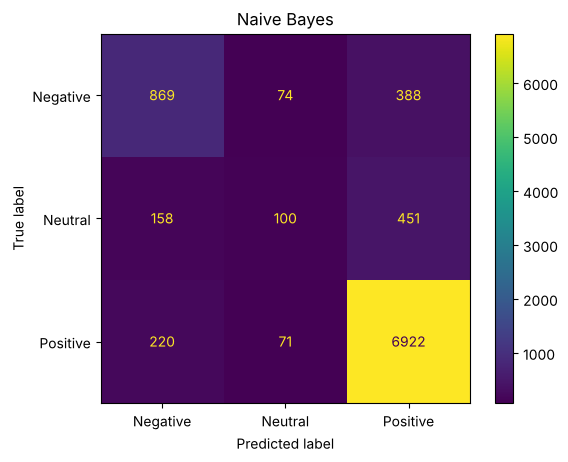

In [4]:
from sklearn.naive_bayes import MultinomialNB
import time

naive_bayes = MultinomialNB()

# Time how long training takes (for the comparison table)
start = time.time()
naive_bayes.fit(train_bow, train_labels)
training_seconds = time.time() - start
print(f"Training time: {training_seconds:.2f} seconds")
print()

naive_bayes_predictions = naive_bayes.predict(test_bow)

summary_scores(test_labels, naive_bayes_predictions)
print()
evaluate("Naive Bayes", test_labels, naive_bayes_predictions)

Neutral reviews

In [5]:
# How many of the neutral test reviews did Naive Bayes label correctly?
neutral = test_labels == "Neutral"
caught = (naive_bayes_predictions[neutral] == "Neutral").sum()
print(f"Neutral reviews caught: {caught} of {neutral.sum()} ({caught / neutral.sum():.0%})")

Neutral reviews caught: 100 of 709 (14%)


Top 10 Words for Positive and Negative

In [6]:
bow_vocabulary = bow.get_feature_names_out()

# feature_log_prob_ holds how likely each word is within each class.
# A word ranks high for Positive when it is much more likely in Positive reviews than in Negative ones.
pos_index = list(naive_bayes.classes_).index("Positive")
neg_index = list(naive_bayes.classes_).index("Negative")
log_ratio = pd.Series(
    naive_bayes.feature_log_prob_[pos_index] - naive_bayes.feature_log_prob_[neg_index],
    index=bow_vocabulary
)

# Only rank words that appear at least 20 times in training, so rare one-off words don't dominate
word_counts = pd.Series(train_bow.sum(axis=0).A1, index=bow_vocabulary)
log_ratio = log_ratio[word_counts >= 20]

top_words_table = pd.DataFrame({
    "Positive word": log_ratio.nlargest(10).index,
    "Positive score": log_ratio.nlargest(10).values.round(2),
    "Negative word": log_ratio.nsmallest(10).index,
    "Negative score": (-log_ratio.nsmallest(10).values).round(2),
}, index=range(1, 11))
top_words_table

,Positive word,Positive score,Negative word,Negative score
1,cravings,3.06,returnable,4.77
2,hooked,2.91,vile,3.76
3,heavenly,2.73,emails,3.65
4,yum,2.71,undrinkable,3.59
5,pleasantly,2.67,deceptive,3.39
6,calm,2.65,yuk,3.37
7,mccann,2.53,ripoff,3.25
8,nom,2.53,worst,3.21
9,winner,2.48,horrid,3.17
10,delish,2.42,ruined,3.12
